# 05 · A/B/Cの一致と条件別分析

主設定L=1を変更せず、L=7・14を含む感度分析を集約します。iALS/BPRは3シードの指標平均とシード間標準偏差を保存し、ユーザー内AUCの区間は各ユーザーのシード平均AUCをユーザー単位で再標本化します。

Aは公式型の時系列holdout：149日以前の同じモデルで150〜210日の正解曲集合を、サンプル候補なしで全カタログから順位付けしたNDCG@10です。Cと単位が異なるため順位だけを比較します。

主順位・感度分析・対応付き差はraw_score（生スコア、設計上高いほど合う）で計算する。ヘッド経由は副表。04z_score_protocol完了を必須とする。

In [1]:
import polars as pl
from IPython.display import display,Image
from relisten import config
from relisten.analysis import collect_model_results,evaluate_task_a,rank_agreements,rq3_strata,paired_model_comparisons,model_cold_coverage
results = collect_model_results()
display(results.filter((pl.col("split")=="test") & (pl.col("route")=="C") & (pl.col("lower_days")==config.LOWER_BOUND_DAYS)))
from relisten.score_protocol import write_score_protocol_report
display(write_score_protocol_report(results))

family,protocol,task,route,split,lower_days,is_main_lower,pairs,users,auc_users,positive_rate,user_auc,user_auc_ci_low,user_auc_ci_high,global_auc,pr_auc,log_loss,brier,seeds,seed_user_auc_std
str,str,str,str,str,i64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64
"""UserBaseline""","""baseline""","""T1""","""C""","""test""",1,true,982716.0,4485.0,3953.0,0.192999,0.5,0.5,0.5,0.614387,0.263604,0.484497,0.154408,1,0.0
"""ACT-R""","""baseline_plus_score""","""T1""","""C""","""test""",1,true,982716.0,4485.0,3953.0,0.192999,0.616118,0.611034,0.621153,0.620661,0.270846,0.482882,0.153781,1,0.0
"""AudioCosine""","""baseline_plus_score""","""T1""","""C""","""test""",1,true,982716.0,4485.0,3953.0,0.192999,0.550597,0.545987,0.555191,0.630025,0.271115,0.476122,0.152077,1,0.0
"""BPR""","""baseline_plus_score""","""T1""","""C""","""test""",1,true,982716.0,4485.0,3953.0,0.192999,0.503664,0.499216,0.508182,0.61389,0.263404,0.484452,0.154447,3,0.000369
"""DecayPop""","""baseline_plus_score""","""T1""","""C""","""test""",1,true,982716.0,4485.0,3953.0,0.192999,0.536516,0.531607,0.541383,0.621529,0.269933,0.482595,0.153669,1,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""DecayPop""","""score_only""","""T2""","""C""","""test""",1,true,967884.0,4819.0,4124.0,0.096279,0.519963,0.514678,0.524862,0.526237,0.122383,0.3161,0.086818,1,0.0
"""ItemKNN""","""score_only""","""T2""","""C""","""test""",1,true,967884.0,4819.0,4124.0,0.096279,0.500486,0.495718,0.505011,0.47139,0.097904,0.317393,0.087121,1,0.0
"""MostPop""","""score_only""","""T2""","""C""","""test""",1,true,967884.0,4819.0,4124.0,0.096279,0.507429,0.502166,0.512431,0.519231,0.115138,0.385707,0.108432,1,0.0


family,protocol,task,route,split,lower_days,is_main_lower,user_auc,user_auc_ci_low,user_auc_ci_high,seeds,fallback_pairs_per_seed
str,str,str,str,str,i64,bool,f64,f64,f64,i64,f64
"""MostPop""","""percentile_head""","""T2""","""C""","""validation""",1,true,0.517365,0.510441,0.524814,1,96288.0
"""MostPop""","""percentile_head""","""T2""","""C""","""test""",1,true,0.505534,0.500331,0.510425,1,381645.0
"""MostPop""","""percentile_head""","""T1""","""C""","""validation""",1,true,0.535369,0.529853,0.541079,1,98699.0
"""MostPop""","""percentile_head""","""T1""","""C""","""test""",1,true,0.525507,0.5209,0.529746,1,219242.0
"""DecayPop""","""percentile_head""","""T2""","""C""","""validation""",1,true,0.547339,0.539509,0.555488,1,96288.0
…,…,…,…,…,…,…,…,…,…,…,…
"""SASRec""","""percentile_head""","""T1""","""C""","""test""",1,true,0.543159,0.538754,0.547513,1,219242.0
"""Recent7dPlays""","""percentile_head""","""T2""","""C""","""validation""",1,true,0.520339,0.513574,0.52657,1,96288.0
"""Recent7dPlays""","""percentile_head""","""T2""","""C""","""test""",1,true,0.532577,0.527871,0.536974,1,381645.0


## モデル間の対応付き差

実行可能な全モデルと3シードが揃ってから、同じpair_id・ユーザー・ラベルでユーザー内AUCを比較します。各ユーザーのシード平均AUCを先に求め、モデル間の差をユーザー単位で1000回再標本化します。全モデル対と、テスト順位上位3種の全対を別表に保存します。上位表は全対の事後的な抜粋で、区間は多重比較未補正です。

raw_scoreの差が主。従来のscore_only/baseline_plus_scoreの差も副指標として保存する。Recent7dPlaysとpercentile_headは主9種の比較に含めない。

In [2]:
display(paired_model_comparisons())
display(pl.read_csv(config.RESULTS / "top_model_paired_differences.csv"))
display(model_cold_coverage())
from relisten.reporting import write_benchmark_report
display(write_benchmark_report(results))

task,protocol,route,lower_days,left_model,right_model,left_rank,right_rank,left_user_auc,right_user_auc,paired_users,mean_auc_difference,difference_ci_low,difference_ci_high
str,str,str,i64,str,str,i64,i64,f64,f64,i64,f64,f64,f64
"""T2""","""raw_score""","""C""",1,"""AudioCosine""","""SASRec""",1,2,0.561862,0.531674,4124,0.030188,0.023298,0.037633
"""T2""","""raw_score""","""C""",1,"""AudioCosine""","""DecayPop""",1,3,0.561862,0.519537,4124,0.042325,0.035241,0.049781
"""T2""","""raw_score""","""C""",1,"""AudioCosine""","""ACT-R""",1,4,0.561862,0.51052,4124,0.051342,0.045272,0.057052
"""T2""","""raw_score""","""C""",1,"""AudioCosine""","""MostPop""",1,5,0.561862,0.507429,4124,0.054433,0.047318,0.061845
"""T2""","""raw_score""","""C""",1,"""AudioCosine""","""iALS""",1,6,0.561862,0.501084,4124,0.060779,0.053863,0.067679
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""T1""","""baseline_plus_score""","""C""",1,"""MostPop""","""iALS""",5,7,0.529671,0.491455,3953,0.038215,0.029666,0.046597
"""T1""","""baseline_plus_score""","""C""",1,"""MostPop""","""SASRec""",5,8,0.529671,0.455199,3953,0.074471,0.066781,0.082015
"""T1""","""baseline_plus_score""","""C""",1,"""BPR""","""iALS""",6,7,0.503664,0.491455,3953,0.012208,0.009076,0.015293


task,protocol,route,lower_days,left_model,right_model,left_rank,right_rank,left_user_auc,right_user_auc,paired_users,mean_auc_difference,difference_ci_low,difference_ci_high
str,str,str,i64,str,str,i64,i64,f64,f64,i64,f64,f64,f64
"""T2""","""raw_score""","""C""",1,"""AudioCosine""","""SASRec""",1,2,0.561862,0.531674,4124,0.030188,0.023298,0.037633
"""T2""","""raw_score""","""C""",1,"""AudioCosine""","""DecayPop""",1,3,0.561862,0.519537,4124,0.042325,0.035241,0.049781
"""T2""","""raw_score""","""C""",1,"""SASRec""","""DecayPop""",2,3,0.531674,0.519537,4124,0.012137,0.008292,0.016416
"""T2""","""score_only""","""C""",1,"""AudioCosine""","""SASRec""",1,2,0.561862,0.531674,4124,0.030188,0.023298,0.037633
"""T2""","""score_only""","""C""",1,"""AudioCosine""","""DecayPop""",1,3,0.561862,0.519963,4124,0.041899,0.034798,0.049346
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""T1""","""score_only""","""C""",1,"""ACT-R""","""AudioCosine""",1,3,0.616118,0.550597,3953,0.065521,0.059246,0.071902
"""T1""","""score_only""","""C""",1,"""ItemKNN""","""AudioCosine""",2,3,0.559807,0.550597,3953,0.009211,0.003184,0.015373
"""T1""","""baseline_plus_score""","""C""",1,"""ACT-R""","""ItemKNN""",1,2,0.616118,0.559807,3953,0.056311,0.049786,0.063138


model,lower_days,task,split,pairs,cold_pairs,cold_fraction
str,i64,str,str,i64,i64,f64
"""ItemKNN""",1,"""T1""","""test""",982716,31341,0.031892
"""ItemKNN""",1,"""T1""","""validation""",488857,1844,0.003772
"""ItemKNN""",1,"""T2""","""train""",755797,120873,0.159928
"""ItemKNN""",1,"""T2""","""test""",967884,322179,0.332869
"""ItemKNN""",1,"""T1""","""train""",418556,6158,0.014712
…,…,…,…,…,…,…
"""SASRec""",14,"""T2""","""test""",905038,185757,0.205248
"""SASRec""",14,"""T1""","""test""",934770,18957,0.02028
"""SASRec""",14,"""T1""","""train""",406678,5003,0.012302


model,status,result,reason
str,str,str,str
"""MostPop""","""completed""","""light_model_metrics.csv""",""""""
"""DecayPop""","""completed""","""light_model_metrics.csv""",""""""
"""ACT-R""","""completed""","""light_model_metrics.csv""",""""""
"""AudioCosine""","""completed""","""light_model_metrics.csv""",""""""
"""ItemKNN""","""completed""","""itemknn_model_metrics.csv""",""""""
"""iALS""","""completed""","""ials_model_metrics.csv""",""""""
"""BPR""","""completed""","""bpr_model_metrics.csv""",""""""
"""SASRec""","""completed""","""sasrec_model_metrics.csv""",""""""
"""SANSA""","""not_run_resource_limit""","""sansa_status.csv""","""Official 50M listens requires …"


## T2 ACT-Rの成分診断

Sのみ、Pのみ、organic再生のみからS/Pを作る版を比べます。主ラベルL=1と感度L=3/7/14は固定です。S+Pが保存済み主ACT-Rと一致することを全ペアで検証します。rawのlift/cosineと候補数は、softmaxと文脈の違いを調べる診断だけに使い、主9種の順位には混ぜません。

In [3]:
from relisten.actr_components import run_component_analysis
component_metrics,component_diagnostics = run_component_analysis()
display(component_metrics.filter((pl.col("route")=="C") & (pl.col("split")=="test") & (pl.col("lower_days")==config.LOWER_BOUND_DAYS) & (pl.col("protocol")=="score_only")))
display(component_diagnostics)
display(pl.read_csv(config.RESULTS / "actr_component_head_directions.csv"))
display(pl.read_csv(config.RESULTS / "actr_component_mechanism_differences.csv"))

model,protocol,task,route,split,lower_days,is_main_lower,pairs,users,auc_users,positive_rate,user_auc,user_auc_ci_low,user_auc_ci_high,global_auc,pr_auc,log_loss,brier
str,str,str,str,str,i64,bool,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""ACT-R""","""score_only""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.51052,0.506406,0.515038,0.565916,0.125519,0.316887,0.087018
"""AudioCosine""","""score_only""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.561862,0.557,0.566788,0.596227,0.129059,0.31339,0.08637
"""ACT-R-S-only""","""score_only""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.503799,0.501355,0.506371,0.511405,0.101245,0.317006,0.087036
"""ACT-R-P-only""","""score_only""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.509981,0.505385,0.514604,0.560863,0.125153,0.316742,0.087
"""ACT-R-organic-SP""","""score_only""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.469392,0.464815,0.474187,0.54549,0.109158,0.315069,0.086772
"""ACT-R-S-raw""","""score_only""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.520177,0.516527,0.524005,0.502451,0.095826,0.316964,0.087031
"""ACT-R-P-raw""","""score_only""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.502654,0.498126,0.506986,0.497911,0.095461,0.317053,0.087047
"""ACT-R-candidate-count""","""score_only""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.529804,0.524468,0.535115,0.564026,0.126031,0.318395,0.087111


split,pairs,s_target_exact_zero_fraction,s_self_mass_above_099_fraction,s_max_mass_above_099_fraction,organic_context_fraction,partial_audio_available_fraction,organic_context_available_fraction,median_candidate_count
str,i64,f64,f64,f64,f64,f64,f64,f64
"""test""",967884,0.860192,0.742575,0.742807,0.035287,0.940268,0.93943,1579.0
"""train""",755797,0.925196,0.797508,0.797698,0.032027,0.931812,0.918657,752.0
"""validation""",283134,0.942525,0.803439,0.803701,0.033751,0.93584,0.937196,1430.0


model,split,lower_days,scaled_head_coefficient,head_direction,raw_global_auc,raw_user_auc
str,str,i64,f64,str,f64,f64
"""ACT-R""","""train""",1,0.033146,"""positive""",0.538625,0.504866
"""ACT-R""","""validation""",1,0.033146,"""positive""",0.555983,0.499974
"""ACT-R""","""test""",1,0.033146,"""positive""",0.565916,0.51052
"""AudioCosine""","""train""",1,0.400352,"""positive""",0.601474,0.561508
"""AudioCosine""","""validation""",1,0.400352,"""positive""",0.601729,0.568328
…,…,…,…,…,…,…
"""ACT-R-P-raw""","""validation""",1,-0.000572,"""negative""",0.505024,0.50074
"""ACT-R-P-raw""","""test""",1,-0.000572,"""negative""",0.502089,0.497346
"""ACT-R-candidate-count""","""train""",1,-0.135279,"""negative""",0.45856,0.4844


left_model,right_model,lower_days,task,route,split,protocol,paired_users,mean_auc_difference,difference_ci_low,difference_ci_high
str,str,i64,str,str,str,str,i64,f64,f64,f64
"""ACT-R""","""ACT-R-P-only""",1,"""T2""","""C""","""test""","""score_only""",4124,0.000539,-0.002124,0.003345
"""ACT-R-S-raw""","""ACT-R-S-only""",1,"""T2""","""C""","""test""","""score_only""",4124,0.016378,0.012383,0.020264
"""ACT-R-P-only""","""ACT-R-P-raw""",1,"""T2""","""C""","""test""","""score_only""",4124,0.007327,-0.000929,0.016253
"""ACT-R-candidate-count""","""ACT-R""",1,"""T2""","""C""","""test""","""score_only""",4124,0.019284,0.013218,0.0248
"""ACT-R""","""ACT-R-P-only""",3,"""T2""","""C""","""test""","""score_only""",4073,0.000025,-0.0029,0.002907
…,…,…,…,…,…,…,…,…,…,…
"""ACT-R-candidate-count""","""ACT-R""",7,"""T2""","""C""","""test""","""score_only""",3997,0.019063,0.013126,0.025487
"""ACT-R""","""ACT-R-P-only""",14,"""T2""","""C""","""test""","""score_only""",3820,-0.001183,-0.004394,0.001815
"""ACT-R-S-raw""","""ACT-R-S-only""",14,"""T2""","""C""","""test""","""score_only""",3820,0.015281,0.010962,0.019489


In [4]:
task_a = evaluate_task_a()
display(task_a)
display(rank_agreements(results,task_a))

task A audio/ACT-R 0/6323 users


task A audio/ACT-R 320/6323 users


task A audio/ACT-R 640/6323 users


task A audio/ACT-R 960/6323 users


task A audio/ACT-R 1280/6323 users


...

task A audio/ACT-R 5440/6323 users


task A audio/ACT-R 5760/6323 users


task A audio/ACT-R 6080/6323 users


model,seed,ndcg_at_10
str,i64,f64
"""MostPop""",42,0.168978
"""DecayPop""",42,0.226809
"""ItemKNN""",42,0.36852
"""iALS""",41,0.402687
"""iALS""",42,0.402537
…,…,…
"""BPR""",42,0.319854
"""BPR""",43,0.320331
"""AudioCosine""",42,0.051773


comparison,models,kendall_tau,p_value
str,i64,f64,f64
"""ndcg_at_10_vs_C""",8,-0.285714,0.39876
"""B_vs_C""",8,0.642857,0.031151


## ACT-Rの経路別base-level

全経路版のbaseだけを自発のみ・推薦のみへ置き換えます。T2は全版でbaseを使わないため同値です。S/Pと候補集合は固定し、主モデル順位とは別表で報告します。

In [5]:
from relisten.actr_analysis import build_base_variant_features
from relisten.evaluation import evaluate_features
variants = build_base_variant_features()
variant_metrics = evaluate_features(variants,{"ACT-R-organic-base":"organic_base","ACT-R-recommendation-base":"recommendation_base"},"actr_base_metrics.csv",artifact_root=config.PROCESSED/"actr_base_diagnostics")
display(variant_metrics.filter((pl.col("route")=="C") & (pl.col("split")=="test") & (pl.col("lower_days")==config.LOWER_BOUND_DAYS)))

ACT-R base variants 0/6813 users


ACT-R base variants 500/6813 users


ACT-R base variants 1000/6813 users


ACT-R base variants 1500/6813 users


ACT-R base variants 2000/6813 users


...

evaluated L=14 T2 C


evaluated L=14 T2 B


evaluated L=14 T1 C


evaluated L=14 T1 B


model,protocol,task,route,split,lower_days,is_main_lower,pairs,users,auc_users,positive_rate,user_auc,user_auc_ci_low,user_auc_ci_high,global_auc,pr_auc,log_loss,brier
str,str,str,str,str,i64,bool,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""UserBaseline""","""baseline""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.5,0.5,0.5,0.607669,0.135043,0.31237,0.086232
"""ACT-R-organic-base""","""score_only""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.51052,0.506406,0.515038,0.565916,0.125519,0.316887,0.087018
"""ACT-R-organic-base""","""baseline_plus_score""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.51052,0.506406,0.515038,0.612849,0.137161,0.312243,0.086209
"""ACT-R-recommendation-base""","""score_only""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.51052,0.506406,0.515038,0.565916,0.125519,0.316887,0.087018
"""ACT-R-recommendation-base""","""baseline_plus_score""","""T2""","""C""","""test""",1,true,967884,4819,4124,0.096279,0.51052,0.506406,0.515038,0.612849,0.137161,0.312243,0.086209
"""UserBaseline""","""baseline""","""T1""","""C""","""test""",1,true,982716,4485,3953,0.192999,0.5,0.5,0.5,0.614387,0.263604,0.484497,0.154408
"""ACT-R-organic-base""","""score_only""","""T1""","""C""","""test""",1,true,982716,4485,3953,0.192999,0.595305,0.590234,0.600565,0.547854,0.261646,0.489828,0.155487
"""ACT-R-organic-base""","""baseline_plus_score""","""T1""","""C""","""test""",1,true,982716,4485,3953,0.192999,0.595305,0.590234,0.600565,0.616925,0.266671,0.483773,0.15413
"""ACT-R-recommendation-base""","""score_only""","""T1""","""C""","""test""",1,true,982716,4485,3953,0.192999,0.508099,0.503529,0.512779,0.53288,0.216155,0.490464,0.155723


## RQ3

活動量・人気度・履歴長・好みへの近さ・初回再生率・24時間内のLike別に測ります。未来活動量とLikeは記述的な層別専用で、予測器には入力しません。分位の境界は特徴分布だけから作り、モデル精度で選びません。

family,protocol,task,stratifier,stratum,lower_days,pairs,users,auc_users,positive_rate,user_auc,user_auc_ci_low,user_auc_ci_high,global_auc,pr_auc,log_loss,brier,seeds
str,str,str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""MostPop""","""raw_score""","""T1""","""like""","""true""",1,8110.0,1729.0,275.0,0.800493,0.513318,0.471137,0.556977,0.619569,0.850018,null,null,1
"""iALS""","""raw_score""","""T1""","""history""","""Q3""",1,281455.0,1281.0,1179.0,0.202409,0.506248,0.49837,0.514678,0.484654,0.198573,null,null,3
"""MostPop""","""raw_score""","""T1""","""closeness""","""Q1""",1,194713.0,3858.0,2854.0,0.147741,0.536784,0.529138,0.545402,0.550841,0.178134,null,null,1
"""AudioCosine""","""raw_score""","""T2""","""history""","""Q1""",1,333218.0,2194.0,1727.0,0.109295,0.552497,0.544228,0.560274,0.57888,0.136668,null,null,1
"""DecayPop""","""score_only""","""T1""","""history""","""Q1""",1,154545.0,1890.0,1496.0,0.170941,0.540233,0.530169,0.550293,0.537595,0.213012,0.454935,0.14086,1
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""AudioCosine""","""baseline_plus_score""","""T1""","""played_ratio""","""<50%""",1,302546.0,4298.0,3303.0,0.187449,0.549402,0.542599,0.556423,0.599714,0.248269,0.479722,0.15225,1
"""ItemKNN""","""raw_score""","""T2""","""history""","""Q3""",1,206073.0,1292.0,1108.0,0.097014,0.484328,0.474493,0.493557,0.476896,0.098957,null,null,1
"""AudioCosine""","""raw_score""","""T2""","""closeness""","""Q4""",1,192689.0,4113.0,2867.0,0.140267,0.525953,0.517766,0.534028,0.529559,0.153444,null,null,1


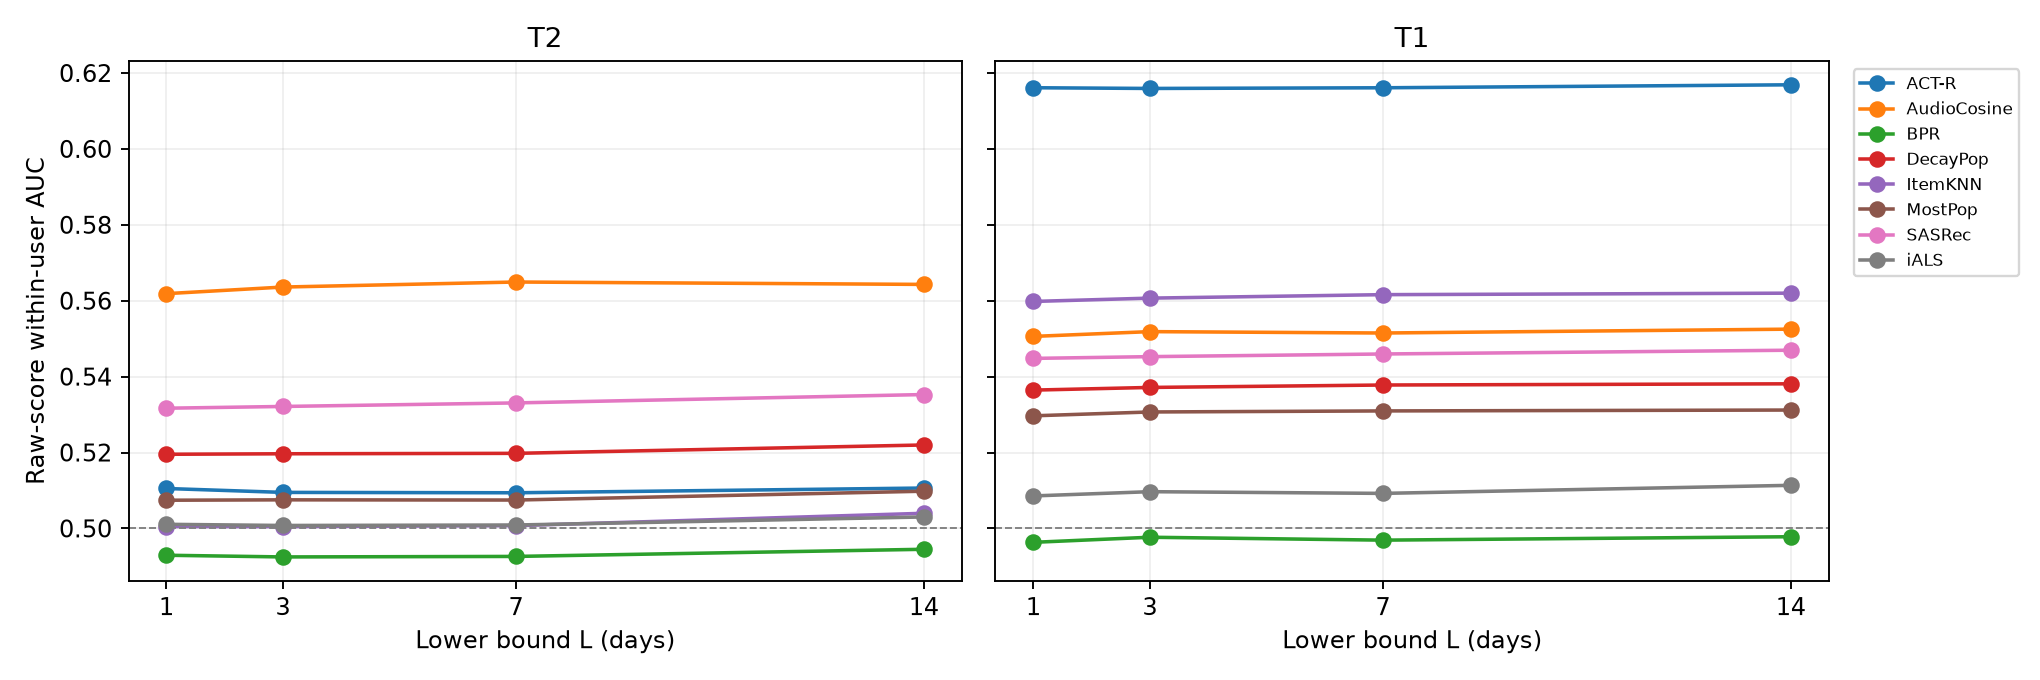

In [6]:
strata = rq3_strata()
display(strata)
display(Image(filename=str(config.RESULTS / "figures/model_lower_bound_sensitivity.png")))

## 限界

SANSAは資源制約のため未計測。学習用29日と評価用149日でモデルの学習量に差があります。Aはユーザーごとの複数正解を持つYambda型holdoutで、各イベントの直後を逐次更新して測るオンライン精度ではありません。End-to-EndのSASRecは補助拡張として主比較とは別に扱います。

In [7]:
from relisten.reporting import write_benchmark_report
display(write_benchmark_report(results))

model,status,result,reason
str,str,str,str
"""MostPop""","""completed""","""light_model_metrics.csv""",""""""
"""DecayPop""","""completed""","""light_model_metrics.csv""",""""""
"""ACT-R""","""completed""","""light_model_metrics.csv""",""""""
"""AudioCosine""","""completed""","""light_model_metrics.csv""",""""""
"""ItemKNN""","""completed""","""itemknn_model_metrics.csv""",""""""
"""iALS""","""completed""","""ials_model_metrics.csv""",""""""
"""BPR""","""completed""","""bpr_model_metrics.csv""",""""""
"""SASRec""","""completed""","""sasrec_model_metrics.csv""",""""""
"""SANSA""","""not_run_resource_limit""","""sansa_status.csv""","""Official 50M listens requires …"
